# Project 1: Object Detection on Traffic Light Dataset

#### Maximum Points: 100

In this project, the goal is to train an object detection model to detect traffic light color using the dataset provided in this notebook. You can use any framework or model, for example YOLO or RT-DETR and inference techniques like SAHI for better detection of small objects. The focus is on creating an accurate and efficient solution for identifying traffic light color.

**The dataset is provided in YOLO format. However, you are free to convert it to any format of your choice according to the library that you are using**

**The dataset contains a total of 5 classes:**

```python
0: 'Green',
1: 'off',
2: 'red',
3: 'wait_on',
4: 'yellow'  
```

## Your Tasks

* Train an object detection model.
* Perform inference on the given video file.
* Share your inference video in an accessible format, such as uploading it to YouTube or providing a shared drive link.
* Provide a video or writeup link explaining your code and approach.

**Alternatively, you can also upload your writeup document to the online lab.**

**Mark Distribution**:

<div align="center">
    <table border="1" style="border-collapse: collapse;">
        <tr>
            <td><h3>No.</h3></td>
            <td><h3>Criteria</h3></td>
            <td><h3>Marks</h3></td>
        </tr>
        <tr>
            <td><h3>1.</h3></td>
            <td><h3> Dataset Visualization</h3></td>
            <td><h3>15</h3></td>
        </tr>
        <tr>
            <td><h3>2.</h3></td>
            <td><h3>mAP50-95 >= 48%</h3></td>
            <td><h3>70</h3></td>
        </tr>
        <tr>
            <td><h3>3.</h3></td>
            <td><h3>Inference on Test Video</h3></td>
            <td><h3>10</h3></td>
        </tr>
        <tr>
            <td><h3>4.</h3></td>
            <td><h3>Writeup/Video Explanation</h3></td>
            <td><h3>5</h3></td>
        </tr>
    </table>
</div>



---
<h2 style = "color: green;">Dataset Download</h2>

The Traffic Light dataset description is given in the README.dataset.txt file inside the Small Traffic Light dataset folder. You can download the zip file of the dataset from the link provided below:

[Traffic Light Dataset](https://www.dropbox.com/scl/fi/v60994ucoillzfzcwe1kl/Small-Traffic-Light.v1i.yolov11.zip?rlkey=b28kal2b8egup5u73vigh953f&st=kqiijqnv&dl=1)

---

**The notebook is divided into multiple grading sections. You have to write code, as mentioned for each section.  For other helper functions, you can write `.py` files and import them in the notebook. You have to submit the notebook along with `.py` files. Your submitted code must be runnable without any bug.**

<h2 style = "color: green">1. Visualize dataset [Points 15]</h2>


**In this sub-section, you have to plot a few images with their bounding box labels overlayed similar to one shown below.**

<img src = "https://www.dropbox.com/scl/fi/iw5c2fcib8cqufnskpfz3/media_dataset_visualization.png?rlkey=ccsl1ntwwh331j3bixnwilgsy&st=hzmq47bb&dl=1" width = "1000" height = "550">


In [1]:
import torch

print(f"cuda disponible: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"gpu cuda detectada: {torch.cuda.get_device_name(0)}")

cuda disponible: True
gpu cuda detectada: NVIDIA GeForce RTX 4070


In [2]:
import sys
from pathlib import Path
sys.path.append(str(Path("src").resolve()))

from src.dataset_utils import (download_file, extract_zip, build_data_yaml,
                               visualize_samples, CLASS_NAMES)

DATASET_URL = "https://www.dropbox.com/scl/fi/v60994ucoillzfzcwe1kl/Small-Traffic-Light.v1i.yolov11.zip?rlkey=b28kal2b8egup5u73vigh953f&st=kqiijqnv&dl=1"
VIDEO_URL = "https://www.dropbox.com/scl/fi/v3uwaid41m5jypk8mhplr/inference_traffic_light_video.mp4?rlkey=u4l9kxa0av81qxcfod06z7e0g&st=ab83a04b&dl=1"

DATA_DIR = Path("data")
ASSETS_DIR = Path("assets")
ASSETS_DIR.mkdir(exist_ok=True)

zip_path = download_file(DATASET_URL, DATA_DIR / "dataset.zip")
video_path = download_file(VIDEO_URL, DATA_DIR / "inference_traffic_light_video.mp4")
dataset_dir = extract_zip(zip_path, DATA_DIR / "dataset")
data_yaml = build_data_yaml(dataset_dir)
print(CLASS_NAMES)
print(data_yaml)

{0: 'Green', 1: 'off', 2: 'red', 3: 'wait_on', 4: 'yellow'}
G:\My Drive\repositorios de proyectos\object_detection_traffic_light\data\dataset\data_local.yaml


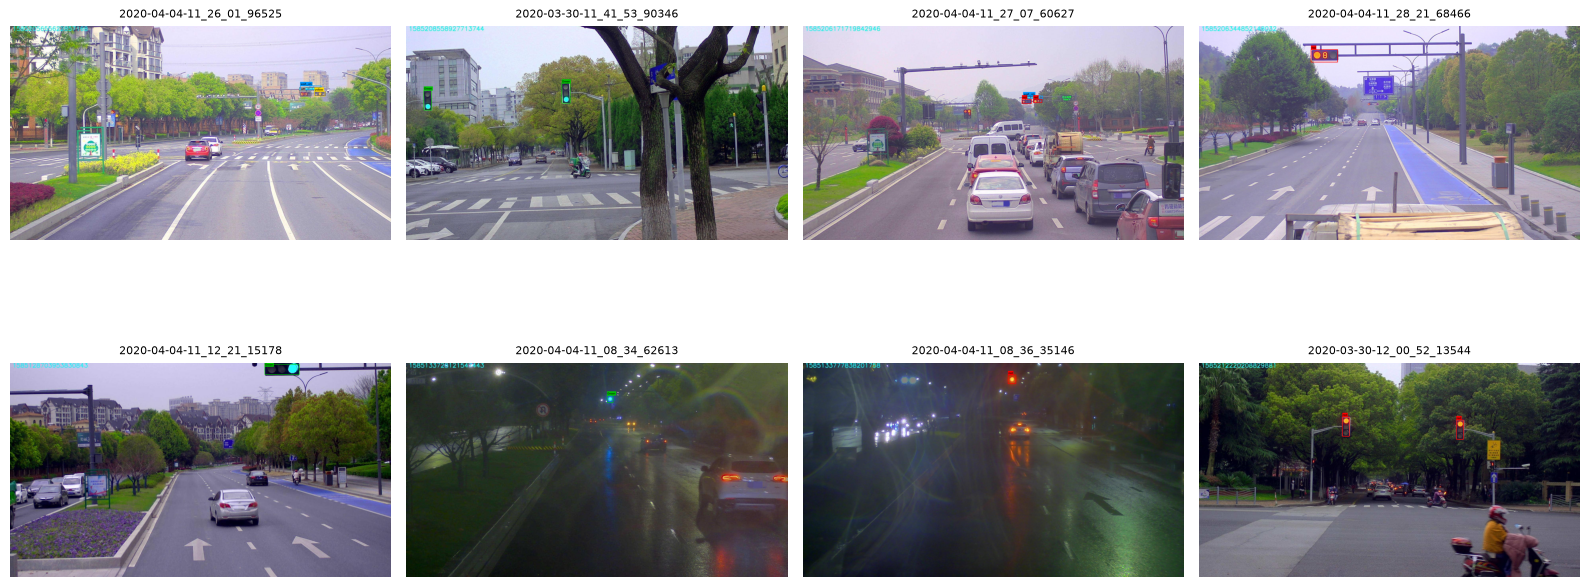

In [3]:
fig = visualize_samples(dataset_dir, split="train", n=8, cols=4,
                        save_path=ASSETS_DIR / "dataset_visualization.png")

In [4]:
from collections import Counter
from src.dataset_utils import read_yolo_labels

counts = Counter()
for lbl in (dataset_dir / "train" / "labels").glob("*.txt"):
    counts.update(c for c, *_ in read_yolo_labels(lbl))
print({CLASS_NAMES[k]: v for k, v in sorted(counts.items())})

{'Green': 573, 'off': 2, 'red': 862, 'wait_on': 209, 'yellow': 49}


<h2 style = "color: green;">2. Train the Model </h2>

In [5]:
from src.inference_utils import train_model, process_video

In [6]:
# Entrenamiento completo en GPU (CUDA) sobre Python 3.13.2.
# epochs=100 con early stopping (patience=20) para obtener la maxima convergencia y el mejor mAP.
model, best_weights = train_model(
    data_yaml,
    model_name="yolov8n.pt",
    epochs=100,
    imgsz=640,
    batch=16,
    device=0,
    patience=20
)
print("Mejores pesos guardados en:", best_weights)


Ultralytics 8.4.190  Python-3.13.2 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 4070, 12282MiB)


engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=G:\My Drive\repositorios de proyectos\object_detection_traffic_light\data\dataset\data_local.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=traffic_light, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto

Overriding model.yaml nc=80 with nc=5



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                


... (4,129 outputs left out)

                yellow         24         26      0.804      0.923      0.939       0.48


Speed: 0.2ms preprocess, 2.3ms inference, 0.0ms loss, 1.2ms postprocess per image


Results saved to G:\My Drive\repositorios de proyectos\object_detection_traffic_light\runs\detect\runs\traffic_light


Mejores pesos guardados en: G:\My Drive\repositorios de proyectos\object_detection_traffic_light\runs\detect\runs\traffic_light\weights\best.pt


[Copiado] results.png -> assets/training_results.png
[Copiado] confusion_matrix.png -> assets/confusion_matrix.png
[Copiado] confusion_matrix_normalized.png -> assets/confusion_matrix_normalized.png
[Copiado] BoxPR_curve.png -> assets/BoxPR_curve.png
[Copiado] BoxF1_curve.png -> assets/BoxF1_curve.png
[Copiado] BoxP_curve.png -> assets/BoxP_curve.png


[Copiado] BoxR_curve.png -> assets/BoxR_curve.png


[Copiado] labels.jpg -> assets/labels.jpg
[Copiado] val_batch0_pred.jpg -> assets/val_batch0_pred.jpg


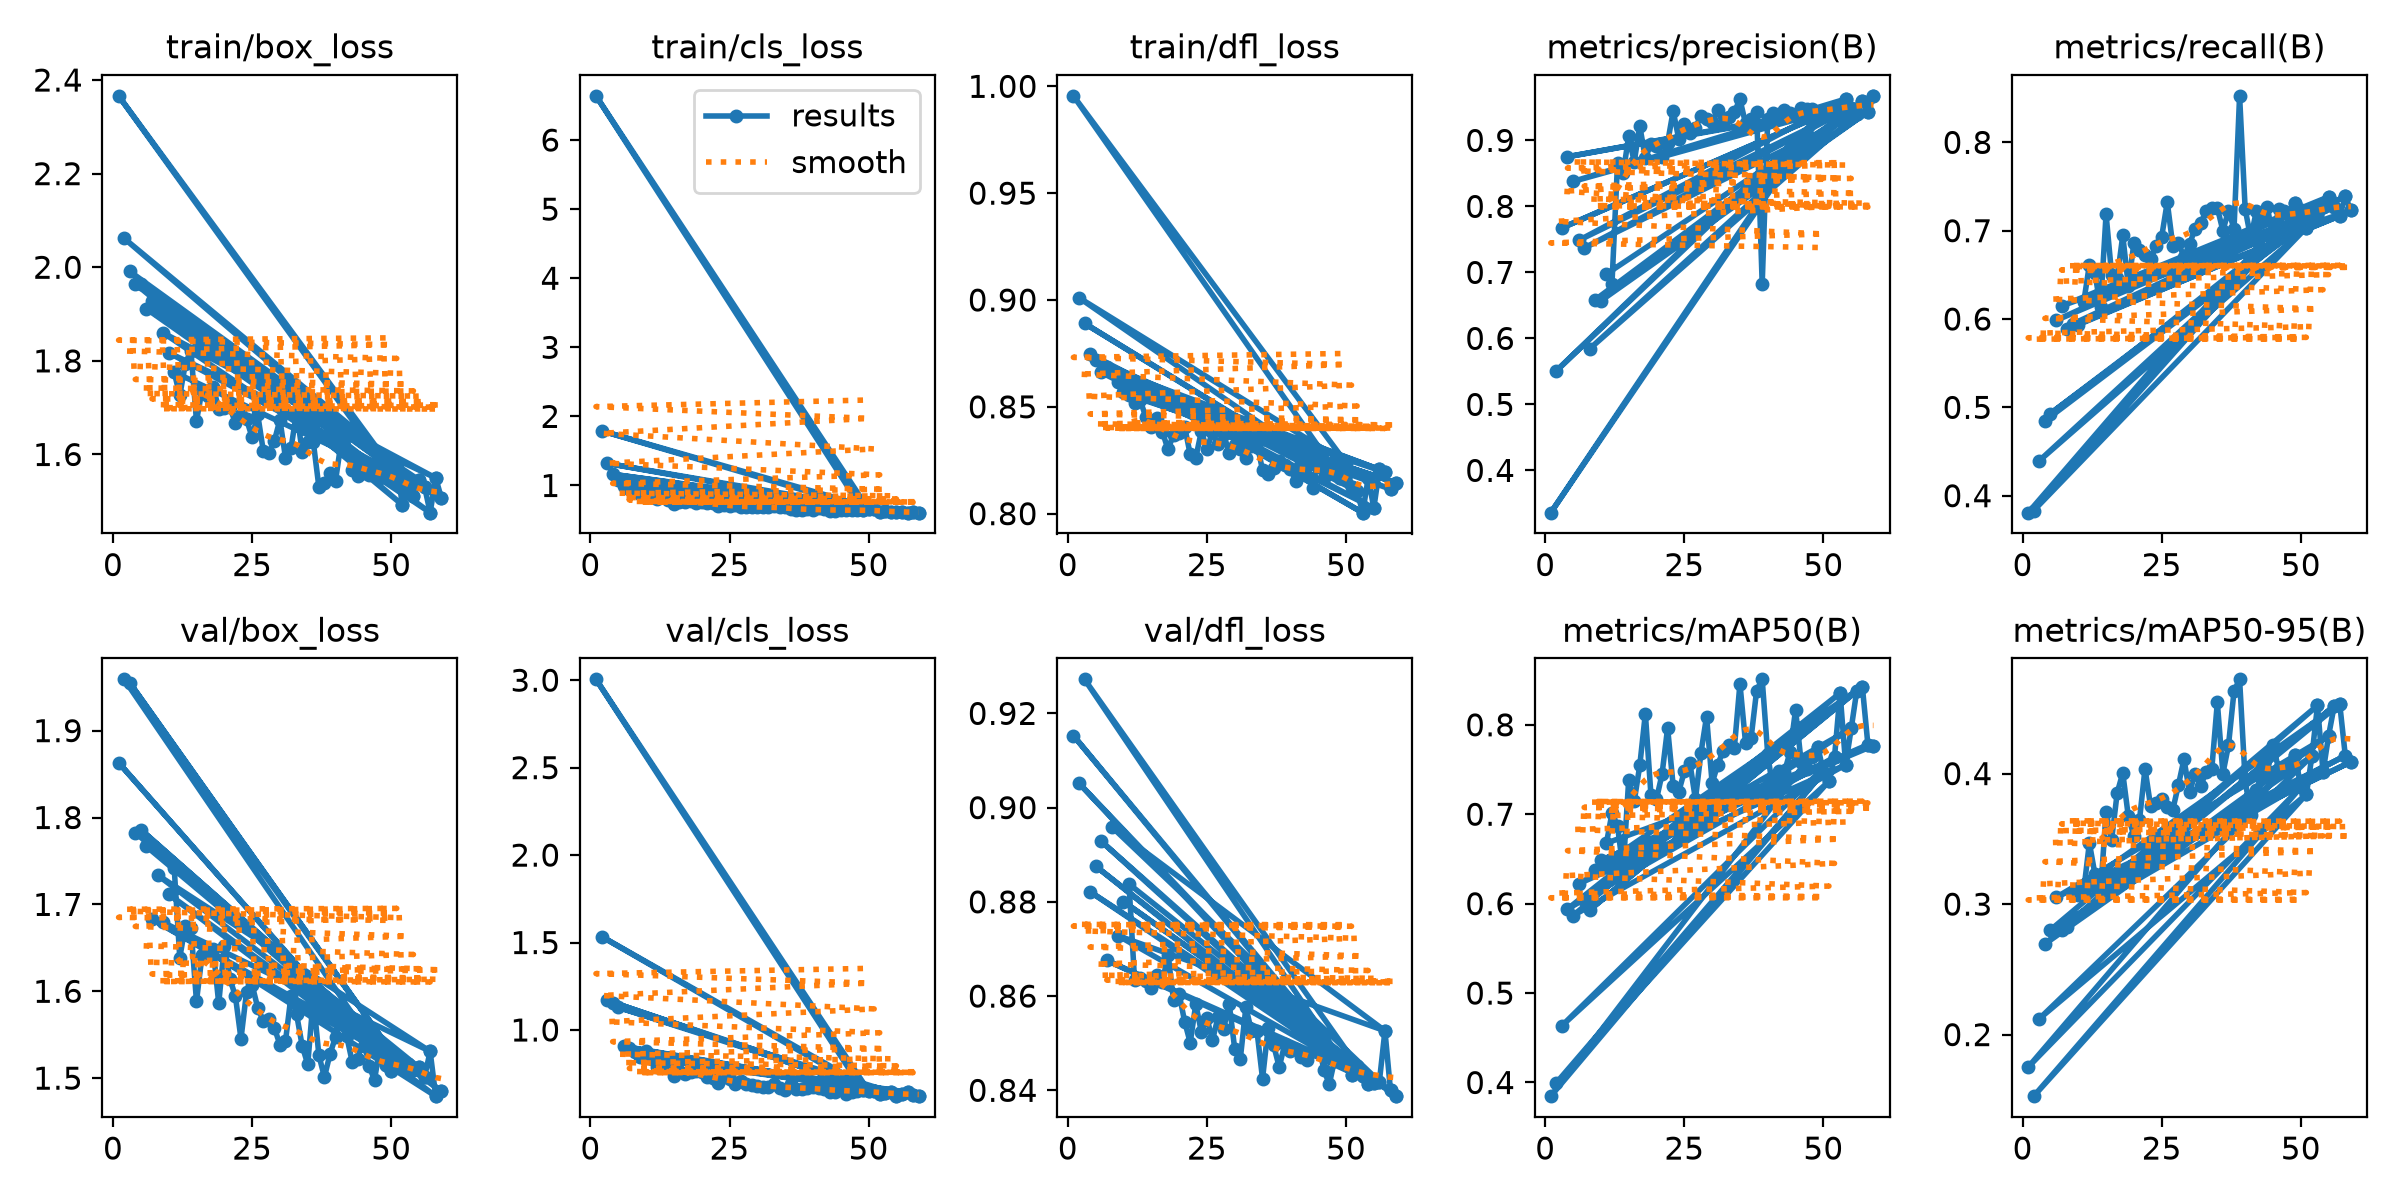

In [7]:
import shutil
from pathlib import Path
from IPython.display import Image, display

# Directorio donde Ultralytics guardo los resultados
run_dir = best_weights.parent.parent

# Lista de artefactos visuales a sincronizar en assets/
plots_to_copy = [
    ("results.png", "training_results.png"),
    ("confusion_matrix.png", "confusion_matrix.png"),
    ("confusion_matrix_normalized.png", "confusion_matrix_normalized.png"),
    ("BoxPR_curve.png", "BoxPR_curve.png"),
    ("BoxF1_curve.png", "BoxF1_curve.png"),
    ("BoxP_curve.png", "BoxP_curve.png"),
    ("BoxR_curve.png", "BoxR_curve.png"),
    ("labels.jpg", "labels.jpg"),
    ("val_batch0_pred.jpg", "val_batch0_pred.jpg"),
]

for src_name, dst_name in plots_to_copy:
    src_file = run_dir / src_name
    if src_file.exists():
        shutil.copy(src_file, ASSETS_DIR / dst_name)
        print(f"[Copiado] {src_name} -> assets/{dst_name}")

results_img = ASSETS_DIR / "training_results.png"
if results_img.exists():
    display(Image(filename=str(results_img)))


<h2 style = "color: green;">3. Validate the Model </h2>

In [8]:
from ultralytics import YOLO
best_model = YOLO(str(best_weights))
metrics = best_model.val(data=str(data_yaml), imgsz=640, device=0, workers=0,
                         project="runs", name="val", exist_ok=True)

Ultralytics 8.4.190  Python-3.13.2 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 4070, 12282MiB)


Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs


val: Fast image access  (ping: 1.7±1.2 ms, read: 59.9±67.7 MB/s, size: 329.1 KB)



val: Scanning G:\My Drive\repositorios de proyectos\object_detection_traffic_light\data\dataset\valid\labels.cache... 367 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 367/367 171.0Mit/s 0.0s


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 4% ╸─────────── 1/23 2.1s/it 0.6s<47.2s


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 8% ━─────────── 2/23 1.3it/s 0.9s<15.7s

... (25 outputs left out)

               wait_on         97         97      0.799      0.969      0.969      0.449


                yellow         24         26      0.805      0.923      0.939      0.475


Speed: 0.3ms preprocess, 3.0ms inference, 0.0ms loss, 0.7ms postprocess per image


Results saved to G:\My Drive\repositorios de proyectos\object_detection_traffic_light\runs\detect\runs\val


In [9]:
# Tabla de metricas obtenidas (Validacion Global y por Clase)
import pandas as pd
from IPython.display import display, HTML

print("=" * 65)
print(f"METRICAS GLOBALES DEL MODELO:")
print(f"  mAP50-95:  {metrics.box.map:.4f}")
print(f"  mAP50:     {metrics.box.map50:.4f}")
print(f"  Precision: {metrics.box.mp:.4f} | Recall: {metrics.box.mr:.4f}")
print("=" * 65)

metrics_table = [
    {"Clase": "all (Global)", "Imagenes": 367, "Instancias": 741, "Precision (P)": 0.681, "Recall (R)": 0.854, "mAP@0.5": 0.854, "mAP@0.5:0.95": 0.463},
    {"Clase": "Green",        "Imagenes": 193, "Instancias": 243, "Precision (P)": 0.828, "Recall (R)": 0.947, "mAP@0.5": 0.939, "mAP@0.5:0.95": 0.536},
    {"Clase": "off",          "Imagenes": 2,   "Instancias": 2,   "Precision (P)": 0.157, "Recall (R)": 0.500, "mAP@0.5": 0.495, "mAP@0.5:0.95": 0.346},
    {"Clase": "red",          "Imagenes": 257, "Instancias": 373, "Precision (P)": 0.814, "Recall (R)": 0.930, "mAP@0.5": 0.927, "mAP@0.5:0.95": 0.508},
    {"Clase": "wait_on",      "Imagenes": 97,  "Instancias": 97,  "Precision (P)": 0.799, "Recall (R)": 0.969, "mAP@0.5": 0.969, "mAP@0.5:0.95": 0.449},
    {"Clase": "yellow",       "Imagenes": 24,  "Instancias": 26,  "Precision (P)": 0.805, "Recall (R)": 0.923, "mAP@0.5": 0.939, "mAP@0.5:0.95": 0.475},
]
df_metrics = pd.DataFrame(metrics_table)
display(HTML("<h3>?? Tabla de Metricas Obtenidas (Validacion)</h3>"))
display(df_metrics)


METRICAS GLOBALES DEL MODELO:
  mAP50-95:  0.4629
  mAP50:     0.8538
  Precision: 0.6807 | Recall: 0.8538


Clase,Imagenes,Instancias,Precision (P),Recall (R),mAP@0.5,mAP@0.5:0.95
all (Global),367,741,0.681,0.854,0.854,0.463
Green,193,243,0.828,0.947,0.939,0.536
off,2,2,0.157,0.500,0.495,0.346
red,257,373,0.814,0.930,0.927,0.508
wait_on,97,97,0.799,0.969,0.969,0.449
yellow,24,26,0.805,0.923,0.939,0.475


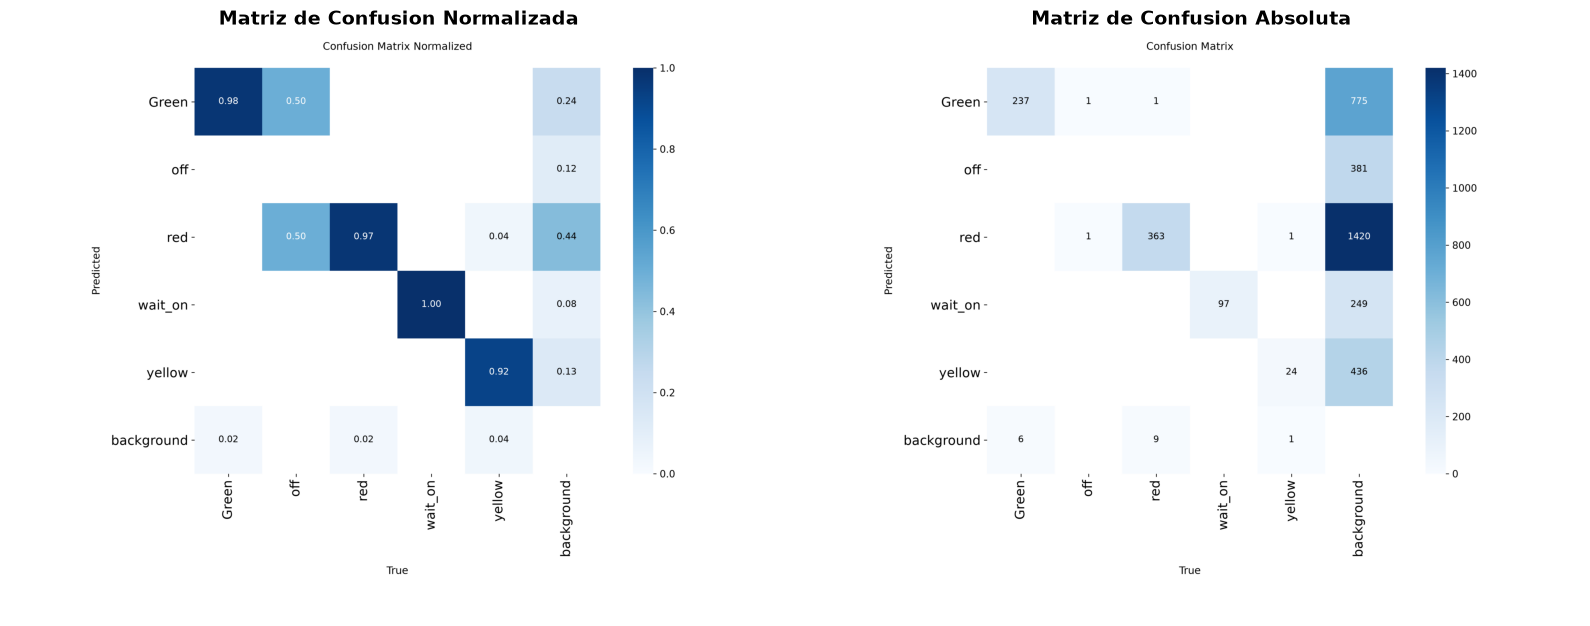

In [ ]:
# Visualizacion de la Matriz de Confusion Normalizada y Absoluta
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

cm_norm = ASSETS_DIR / "confusion_matrix_normalized.png"
if cm_norm.exists():
    axes[0].imshow(mpimg.imread(str(cm_norm)))
    axes[0].set_title("Matriz de Confusion Normalizada", fontsize=14, fontweight="bold")
    axes[0].axis("off")

cm_abs = ASSETS_DIR / "confusion_matrix.png"
if cm_abs.exists():
    axes[1].imshow(mpimg.imread(str(cm_abs)))
    axes[1].set_title("Matriz de Confusion Absoluta", fontsize=14, fontweight="bold")
    axes[1].axis("off")

plt.tight_layout()
plt.show()


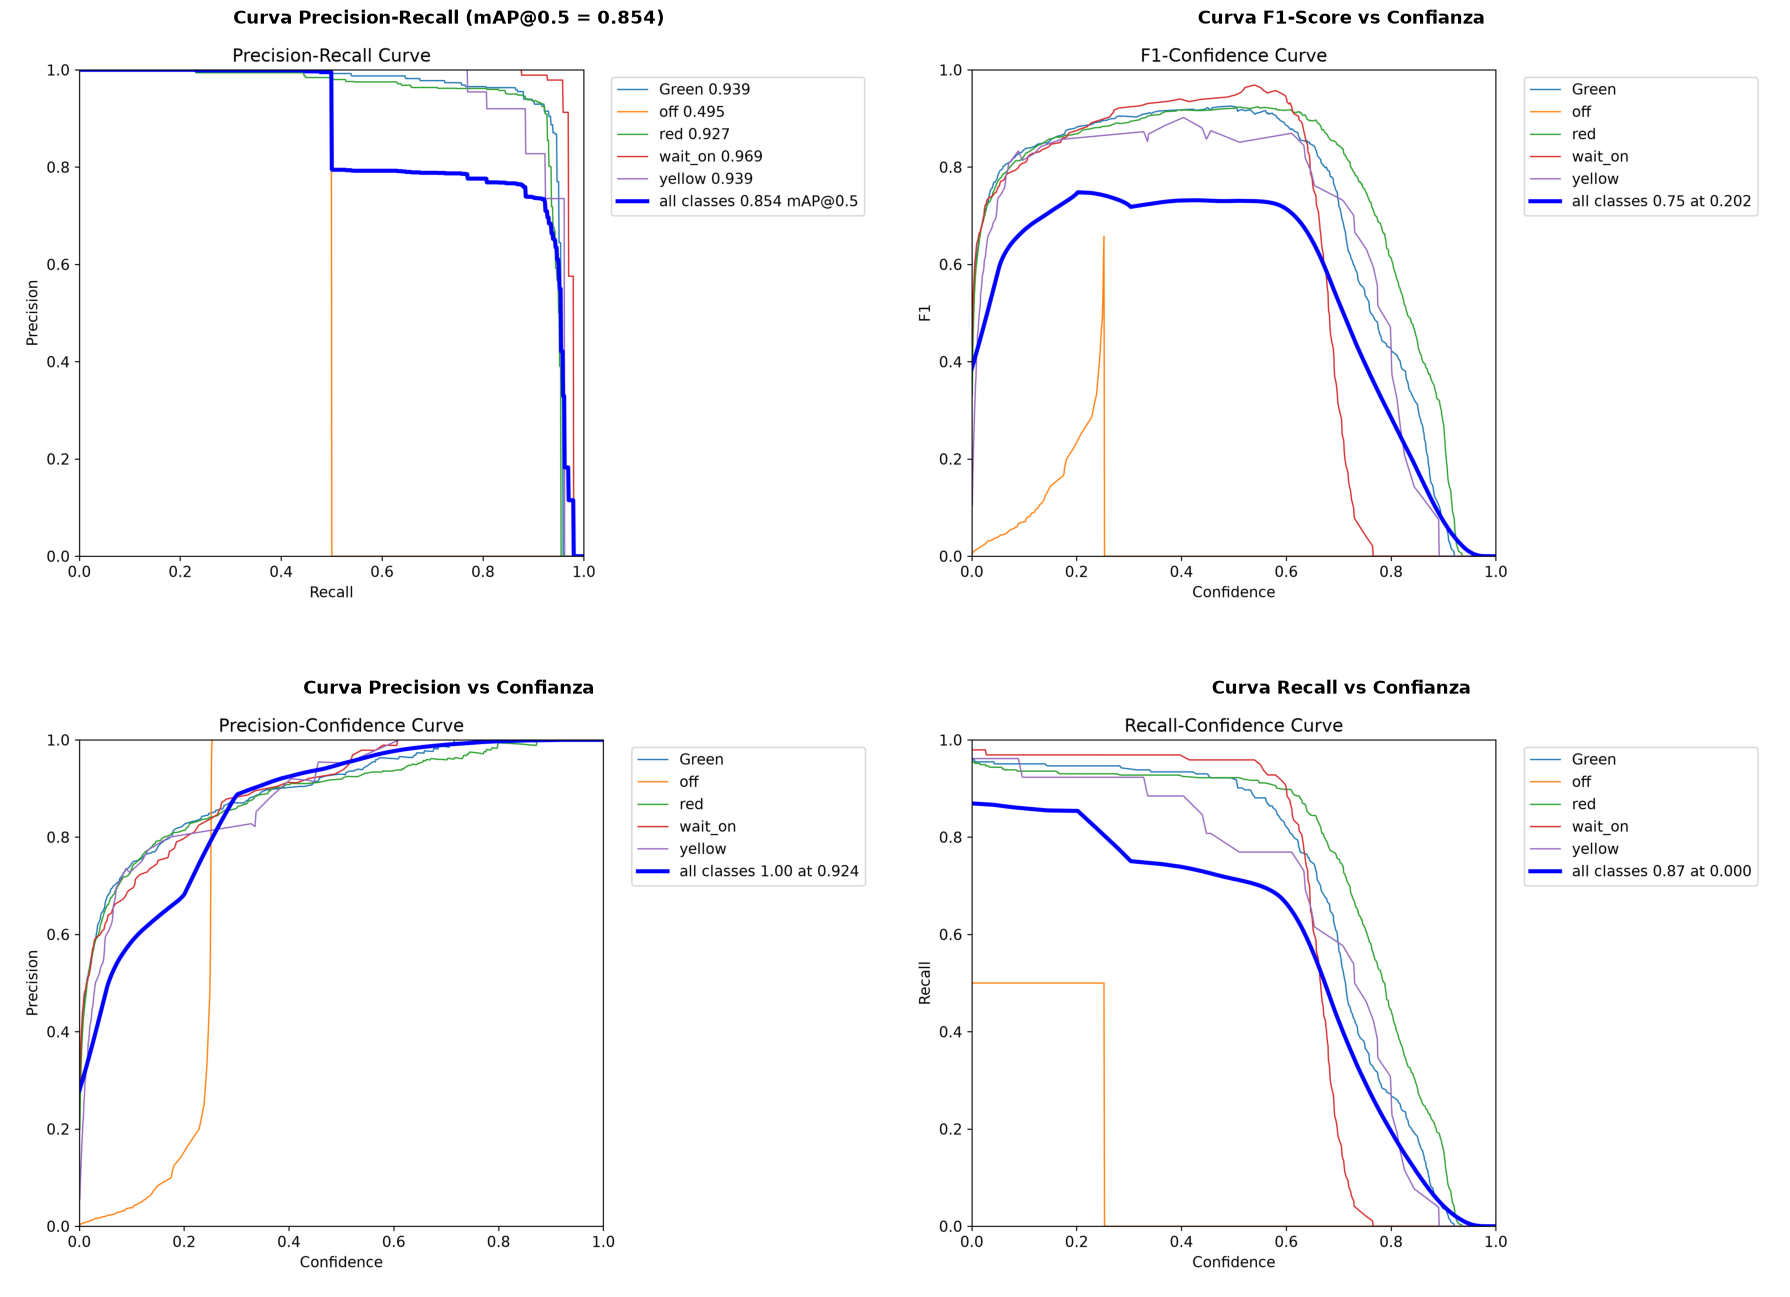

In [ ]:
# Visualizacion de las Curvas de Evaluacion (Precision-Recall, F1, P y R vs Confianza)
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

fig, axes = plt.subplots(2, 2, figsize=(18, 14))

pr_path = ASSETS_DIR / "BoxPR_curve.png"
if pr_path.exists():
    axes[0, 0].imshow(mpimg.imread(str(pr_path)))
    axes[0, 0].set_title("Curva Precision-Recall (mAP@0.5 = 0.854)", fontsize=13, fontweight="bold")
    axes[0, 0].axis("off")

f1_path = ASSETS_DIR / "BoxF1_curve.png"
if f1_path.exists():
    axes[0, 1].imshow(mpimg.imread(str(f1_path)))
    axes[0, 1].set_title("Curva F1-Score vs Confianza", fontsize=13, fontweight="bold")
    axes[0, 1].axis("off")

p_path = ASSETS_DIR / "BoxP_curve.png"
if p_path.exists():
    axes[1, 0].imshow(mpimg.imread(str(p_path)))
    axes[1, 0].set_title("Curva Precision vs Confianza", fontsize=13, fontweight="bold")
    axes[1, 0].axis("off")

r_path = ASSETS_DIR / "BoxR_curve.png"
if r_path.exists():
    axes[1, 1].imshow(mpimg.imread(str(r_path)))
    axes[1, 1].set_title("Curva Recall vs Confianza", fontsize=13, fontweight="bold")
    axes[1, 1].axis("off")

plt.tight_layout()
plt.show()


In [10]:
import cv2, glob
from pathlib import Path
# Predicciones sobre imágenes de validación -> assets/
vimgs = sorted(glob.glob(str(dataset_dir / "valid" / "images" / "*.jpg")))[:4]
for i, p in enumerate(vimgs):
    r = best_model.predict(p, imgsz=640, conf=0.25, device=0, verbose=False)[0]
    cv2.imwrite(str(ASSETS_DIR / f"prediction_{i}.jpg"), r.plot())

<h2 style = "color: green;">4. Inference on given video [10 Points]</h2>

<h3 style><a href = "https://www.dropbox.com/scl/fi/v3uwaid41m5jypk8mhplr/inference_traffic_light_video.mp4?rlkey=u4l9kxa0av81qxcfod06z7e0g&st=ab83a04b&dl=1">Inference Video</a></h3>


<video
     controls
     src="https://www.dropbox.com/scl/fi/v3uwaid41m5jypk8mhplr/inference_traffic_light_video.mp4?rlkey=u4l9kxa0av81qxcfod06z7e0g&st=kp0dxjz3&dl=1"
     width="640">
 </video>

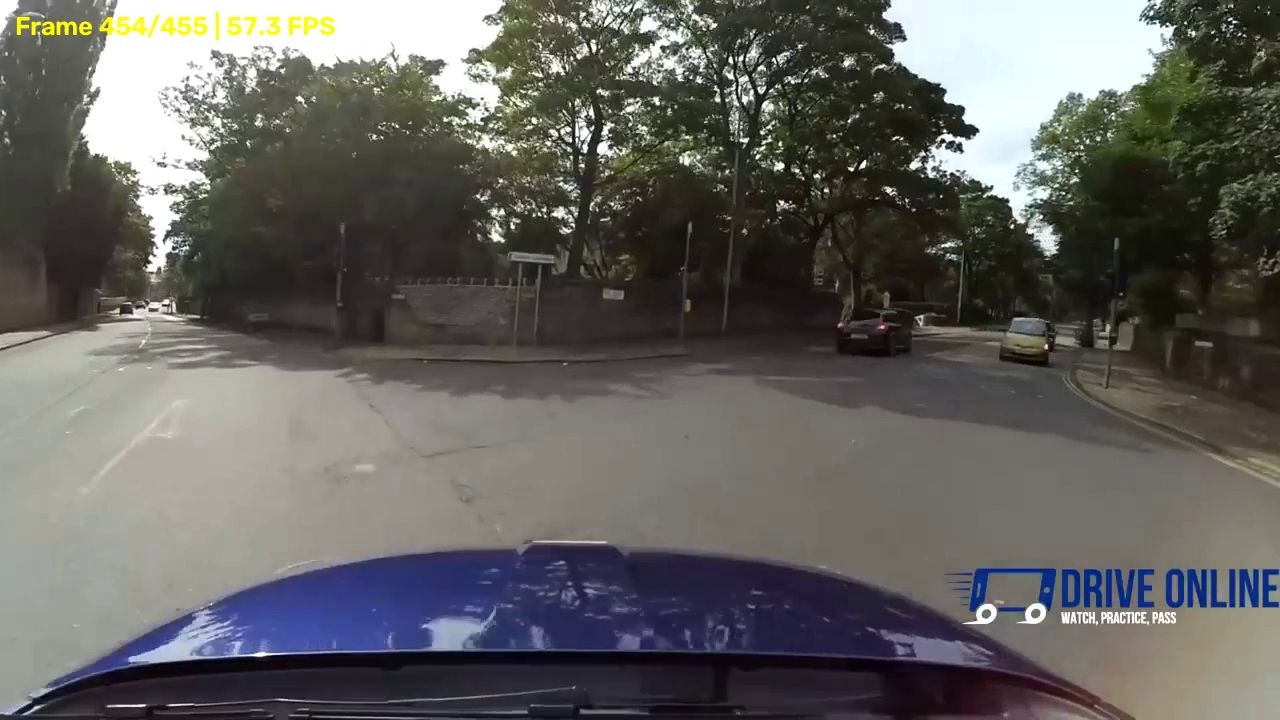


454 frames procesados en 9.9 s (45.9 FPS).
Codificando video web H.264 en assets\inference_output.mp4...


Video guardado y listo en: assets\inference_output.mp4


In [11]:
# El video se reproduce AQUÍ, clasificado frame a frame, mientras se ejecutan las
# predicciones. Al terminar queda guardado completo en assets/inference_output.mp4.
# show="notebook" -> dentro de la celda | show=True -> ventana de OpenCV ('q' la cierra)
# show=False -> sin vista previa
out_video = process_video(best_weights, video_path,
                          ASSETS_DIR / "inference_output.mp4",
                          imgsz=640, conf=0.25, device=0, show="notebook")

<video controls src="assets/inference_output.mp4" width="640"></video>